# Exploratory Data Analysis
Wine Quality dataset (red and white wines)

We start with a description of the prepared dataset, comparing red and white wines, because the
difference between the two types affects both problems. Then we split the EDA in two parts: first
for the regression problem (quality as a number) and then for the classification problem (Low /
Medium / High). We use the clean dataset saved in `01_data_preparation.ipynb`.

## 0. Libraries and plot style

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Colours for the plots
PLUM, PURPLE, LILAC = "#4A1942", "#7D3C98", "#C39BD3"
PINK, ROSE = "#E0719E", "#F5B7C8"
ORANGE, APRICOT = "#E8743B", "#F6A96B"
CREAM, INK = "#FDF1EC", "#3B2A3F"

PALETTE = [PURPLE, PINK, ORANGE, LILAC, APRICOT, PLUM, ROSE]
CLASS_ORDER = ["Low", "Medium", "High"]
CLASS_COLORS = {"Low": PURPLE, "Medium": PINK, "High": ORANGE}
TYPE_COLORS = {"red": PLUM, "white": APRICOT}
CMAP_SEQ = LinearSegmentedColormap.from_list("seq", ["#FFFFFF", ROSE, PINK, PURPLE, PLUM])
CMAP_DIV = LinearSegmentedColormap.from_list("div", [PURPLE, LILAC, "#FFFFFF", APRICOT, ORANGE])

sns.set_theme(style="white", palette=PALETTE)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#CBB8CF", "axes.labelcolor": INK, "axes.titlecolor": PLUM,
    "axes.titleweight": "semibold", "axes.titlesize": 12, "axes.grid": True,
    "grid.color": "#F1E4EC", "xtick.color": INK, "ytick.color": INK,
    "legend.frameon": False, "text.color": INK,
})

FIG_DIR = Path("../results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / name)
    print("Figure saved ->", FIG_DIR / name)

In [2]:
FEATURES = ["fixed acidity", "volatile acidity", "citric acid", "residual sugar",
            "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density",
            "pH", "sulphates", "alcohol"]

wine = pd.read_csv("../data/wine_clean.csv")
wine["quality_class"] = pd.Categorical(wine["quality_class"], categories=CLASS_ORDER, ordered=True)
print(wine.shape)

(5320, 15)


---
# Description of the prepared dataset: red vs white wines

Before looking at each task, we check how different the two wine types are in the 11
physicochemical variables and in `quality`. For each variable we compare both groups with the
**Mann–Whitney U test** (two-sided). It is non-parametric, so it does not assume normality, which
matters for the skewed variables. Because 12 variables are tested, we use the Bonferroni level
$\alpha = 0.05/12 \approx 0.0042$.

With 1,359 red and 3,961 white wines even tiny differences are significant, so we also report an
effect size, **Cliff's delta**:
$\delta = P(X_{red} > X_{white}) - P(X_{red} < X_{white}) = 2U/(n_{red}\,n_{white}) - 1$,
which is the same quantity as the rank-biserial correlation of the Mann–Whitney test. It goes from
−1 (all white values larger) to +1 (all red values larger). We use the thresholds of Romano et al.
(2006): $|\delta| < 0.147$ negligible, $< 0.33$ small, $< 0.474$ medium, otherwise large.

In [3]:
print("Mean quality by wine type:")
print(wine.groupby("wine_type")["quality"].mean().round(2))
print("\nNumber of wines with quality >= 7 by wine type:")
print(wine[wine["quality"] >= 7].groupby("wine_type").size())

Mean quality by wine type:
wine_type
red      5.62
white    5.85
Name: quality, dtype: float64

Number of wines with quality >= 7 by wine type:
wine_type
red      184
white    825
dtype: int64


In [4]:
from scipy import stats

VARS = FEATURES + ["quality"]
ALPHA = 0.05 / len(VARS)
red, white = wine[wine.wine_type == "red"], wine[wine.wine_type == "white"]

def magnitude(d):
    d = abs(d)
    return "negligible" if d < 0.147 else "small" if d < 0.33 else "medium" if d < 0.474 else "large"

rows = []
for col in VARS:
    a, b = red[col].to_numpy(), white[col].to_numpy()
    U, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    delta = 2 * U / (len(a) * len(b)) - 1
    rows.append({"variable": col, "red mean": a.mean(), "red median": np.median(a),
                 "white mean": b.mean(), "white median": np.median(b),
                 "standardised mean difference": (a.mean() - b.mean()) / wine[col].std(),
                 "U statistic": U, "p-value": p, "p-value Bonferroni": min(1.0, p * len(VARS)),
                 "significant": p < ALPHA, "Cliff delta": delta, "magnitude": magnitude(delta)})
rw = pd.DataFrame(rows).set_index("variable")
rw.insert(0, "n red", len(red))
rw.insert(1, "n white", len(white))
rw.to_csv("../results/eda_red_vs_white.csv")
print(f"Bonferroni level: {ALPHA:.5f}")
print(rw["magnitude"].value_counts().to_string())
display(rw.drop(columns=["n red", "n white"]).style.format(
    {"red mean": "{:.3f}", "red median": "{:.3f}", "white mean": "{:.3f}", "white median": "{:.3f}",
     "standardised mean difference": "{:.2f}", "U statistic": "{:.0f}", "p-value": "{:.2e}",
     "p-value Bonferroni": "{:.2e}", "Cliff delta": "{:.3f}"}))

Bonferroni level: 0.00417
magnitude
large         7
small         3
medium        1
negligible    1


,red mean,red median,white mean,white median,standardised mean difference,U statistic,p-value,p-value Bonferroni,significant,Cliff delta,magnitude
variable,,,,,,,,,,,
fixed acidity,8.311,7.900,6.839,6.800,1.11,4220128,4.01e-215,4.82e-214,True,0.568,large
volatile acidity,0.529,0.520,0.281,0.260,1.48,4833412,0.00e+00,0.00e+00,True,0.796,large
citric acid,0.272,0.260,0.334,0.320,-0.42,2129536,1.21e-30,1.45e-29,True,-0.209,small
residual sugar,2.523,2.200,5.915,4.700,-0.75,1908797,8.68e-58,1.04e-56,True,-0.291,small
chlorides,0.088,0.079,0.046,0.042,1.15,5071770,0.00e+00,0.00e+00,True,0.884,large
free sulfur dioxide,15.893,14.000,34.889,33.000,-1.07,851364,1.49e-310,1.78e-309,True,-0.684,large
total sulfur dioxide,46.826,38.000,137.194,133.000,-1.59,272176,0.00e+00,0.00e+00,True,-0.899,large
density,0.997,0.997,0.994,0.994,0.98,4307566,6.05e-240,7.26e-239,True,0.600,large
pH,3.310,3.310,3.195,3.180,0.71,3827712,1.10e-119,1.32e-118,True,0.422,medium


Figure saved -> ../results/figures/eda_red_vs_white_effect_size.png


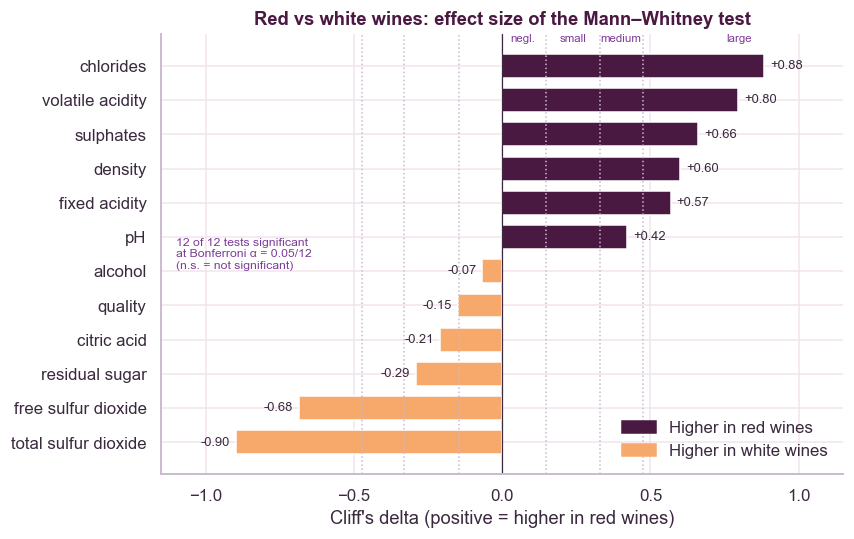

In [5]:
order = rw["Cliff delta"].sort_values().index
fig, ax = plt.subplots(figsize=(8, 5.2))
for x in [0.147, 0.33, 0.474]:
    for s in (-1, 1):
        ax.axvline(s * x, color="#CBB8CF", ls=":", lw=1)
for i, col in enumerate(order):
    d = rw.loc[col, "Cliff delta"]
    ax.barh(i, d, color=TYPE_COLORS["red"] if d > 0 else TYPE_COLORS["white"], edgecolor="white", height=0.7)
    label = f"{d:+.2f}" + ("" if rw.loc[col, "significant"] else "  (n.s.)")
    ax.text(d + (0.02 if d >= 0 else -0.02), i, label, va="center", ha="left" if d >= 0 else "right",
            fontsize=8.5)
ax.set_yticks(range(len(order)), order)
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlim(-1.15, 1.15)
ax.set_xlabel("Cliff's delta (positive = higher in red wines)")
ax.set_title("Red vs white wines: effect size of the Mann–Whitney test")
for x, name in [(0.07, "negl."), (0.24, "small"), (0.40, "medium"), (0.8, "large")]:
    ax.text(x, len(order) - 0.3, name, ha="center", fontsize=7.5, color=PURPLE)
n_sig = int(rw["significant"].sum())
ax.text(-1.1, 5.5, f"{n_sig} of {len(rw)} tests significant\nat Bonferroni α = 0.05/{len(rw)}\n(n.s. = not significant)",
        fontsize=8, color=PURPLE, va="center")
handles = [plt.Rectangle((0, 0), 1, 1, color=TYPE_COLORS[t]) for t in ["red", "white"]]
ax.legend(handles, ["Higher in red wines", "Higher in white wines"], loc="lower right")
save(fig, "eda_red_vs_white_effect_size.png")
plt.show()

All the differences are significant after the Bonferroni correction, but the effect sizes are
very different. Total and free sulfur dioxide, chlorides, volatile acidity, sulphates, density and
fixed acidity have large effects, while alcohol, the variable most related to quality, has a
negligible one. Quality is only slightly higher in white wines (small effect, just above the
negligible threshold).

The boxplots show the six variables with the largest standardised difference between both types.

total sulfur dioxide    1.59
volatile acidity        1.48
chlorides               1.15
sulphates               1.12
fixed acidity           1.11
free sulfur dioxide     1.07
density                 0.98
residual sugar          0.75
pH                      0.71
citric acid             0.42
alcohol                 0.13
dtype: float64


Figure saved -> ../results/figures/eda_red_vs_white.png


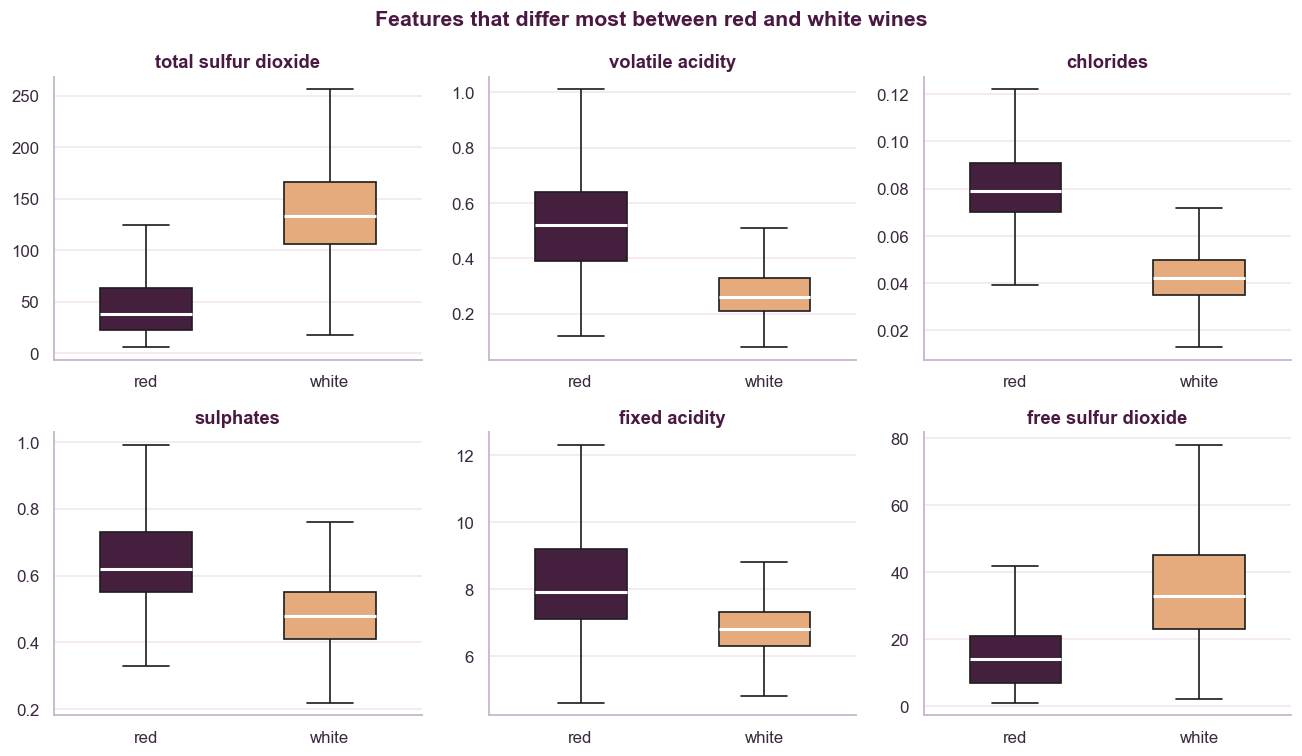

In [6]:
means = wine.groupby("wine_type")[FEATURES].mean()
diff = ((means.loc["red"] - means.loc["white"]) / wine[FEATURES].std()).abs().sort_values(ascending=False)
top6 = diff.index[:6]
print(diff.round(2))

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.flat, top6):
    sns.boxplot(data=wine, x="wine_type", y=col, hue="wine_type", palette=TYPE_COLORS,
                order=["red", "white"], showfliers=False, width=0.5, linewidth=1.1,
                legend=False, ax=ax, medianprops=dict(color="white", linewidth=2))
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Features that differ most between red and white wines",
             color=PLUM, weight="semibold", fontsize=14)
fig.tight_layout()
save(fig, "eda_red_vs_white.png")
plt.show()

---
# A. EDA for regression

### A.1 Distribution of each feature
We cut the x-axis at the 99.5th percentile so a few extreme values don't hide the shape.

Figure saved -> ../results/figures/eda_feature_histograms.png


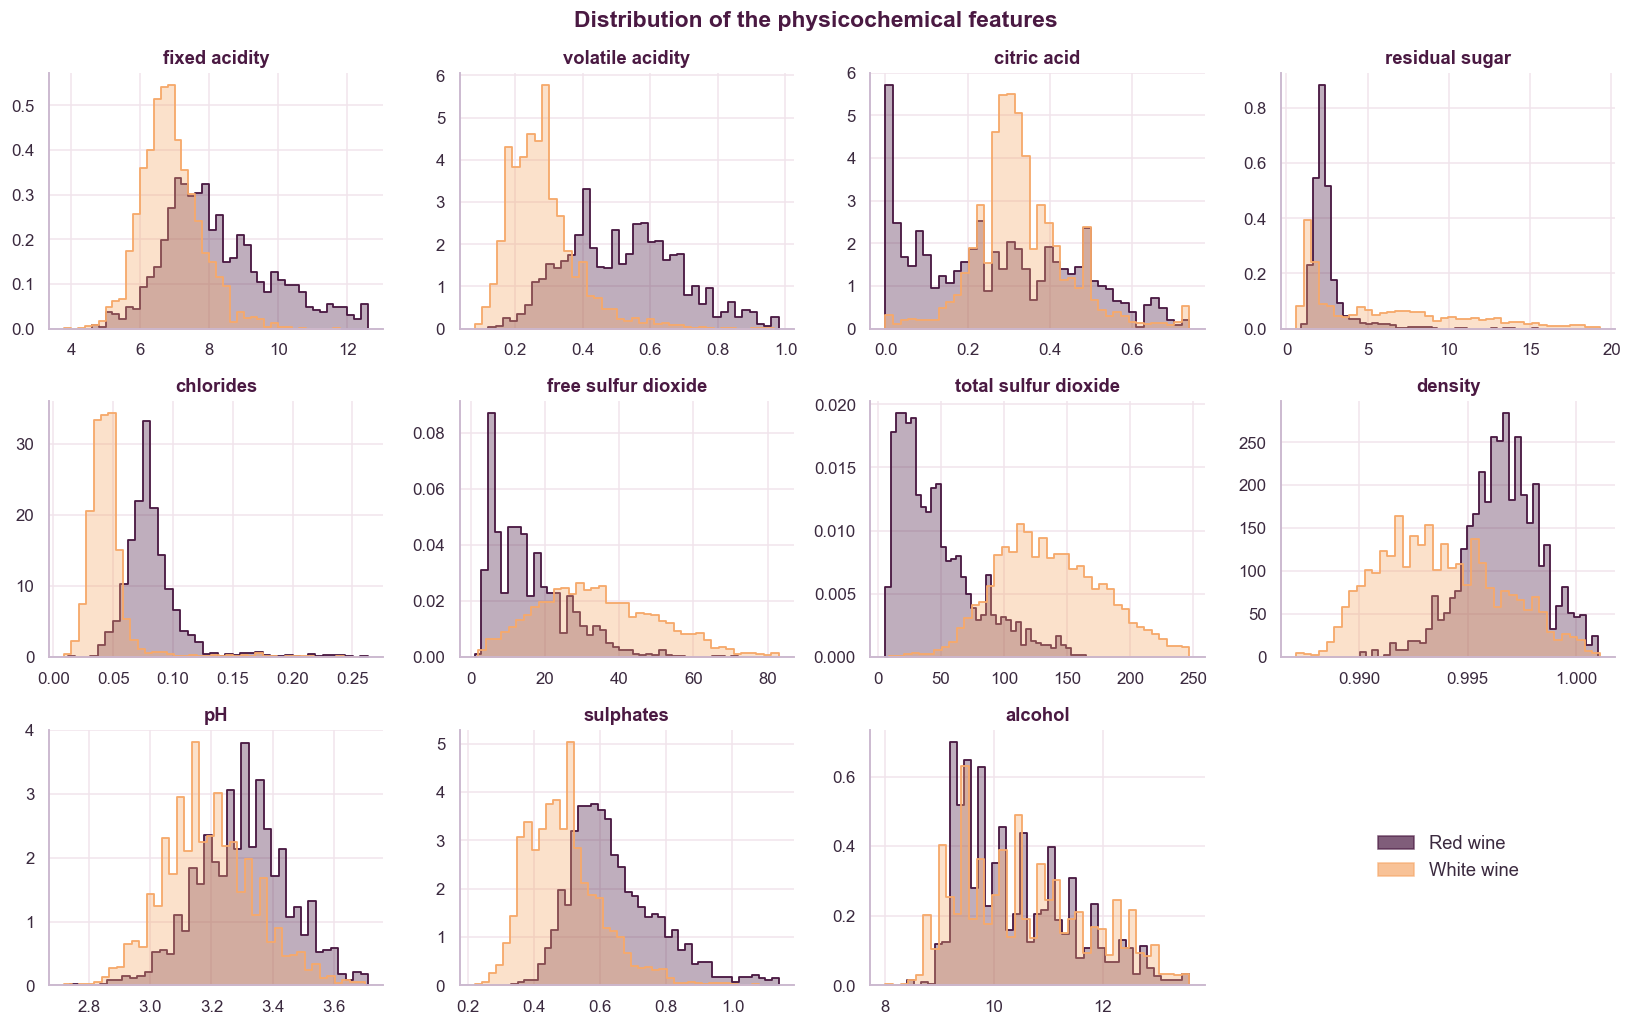

In [7]:
fig, axes = plt.subplots(3, 4, figsize=(15, 9.5))
for ax, col in zip(axes.flat, FEATURES):
    upper = wine[col].quantile(0.995)
    for t in ["red", "white"]:
        values = wine.loc[(wine.wine_type == t) & (wine[col] <= upper), col]
        sns.histplot(values, bins=40, stat="density", element="step", fill=True,
                     alpha=0.35, color=TYPE_COLORS[t], linewidth=1.2, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
axes.flat[-1].axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=TYPE_COLORS[t], alpha=0.7) for t in ["red", "white"]]
axes.flat[-1].legend(handles, ["Red wine", "White wine"], loc="center", fontsize=12)
fig.suptitle("Distribution of the physicochemical features", fontsize=15,
             color=PLUM, weight="semibold")
fig.tight_layout()
save(fig, "eda_feature_histograms.png")
plt.show()

### A.2 Distribution of the target `quality`

Figure saved -> ../results/figures/eda_quality_histogram.png


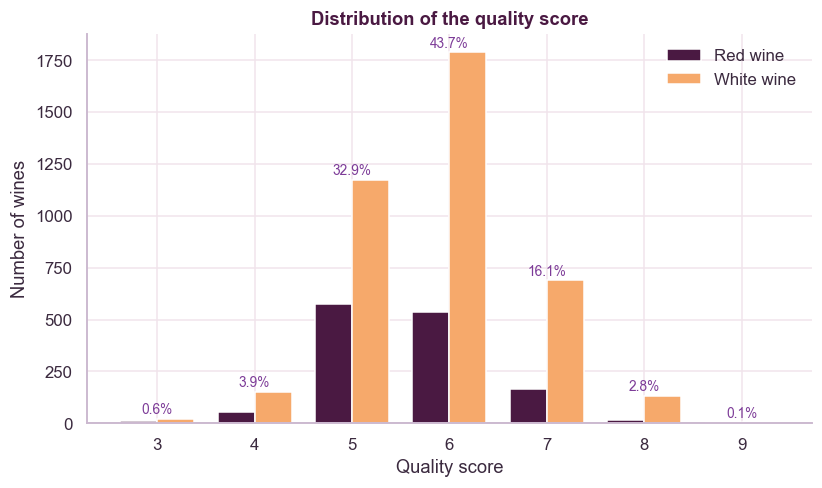

In [8]:
counts = wine.groupby(["quality", "wine_type"]).size().unstack(fill_value=0)
x = np.arange(len(counts))
w = 0.38
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for i, t in enumerate(["red", "white"]):
    ax.bar(x + (i - 0.5) * w, counts[t], width=w, color=TYPE_COLORS[t],
           label=f"{t.capitalize()} wine", edgecolor="white")
total = counts.sum(axis=1)
for xi, n in zip(x, total):
    ax.text(xi, counts.loc[counts.index[xi]].max() + 25, f"{100 * n / total.sum():.1f}%",
            ha="center", fontsize=9, color=PURPLE)
ax.set_xticks(x, counts.index)
ax.set_xlabel("Quality score")
ax.set_ylabel("Number of wines")
ax.set_title("Distribution of the quality score")
ax.legend()
save(fig, "eda_quality_histogram.png")
plt.show()

Most wines have a score of 5 or 6, and very bad (3-4) or very good (8-9) wines are rare. A
regression model will probably predict the common scores well and push the extreme ones towards
the middle.

### A.3 Scatter plot: alcohol vs quality
Quality is an integer, so we add a small random jitter to see where the points concentrate.

Figure saved -> ../results/figures/eda_scatter_alcohol_quality.png


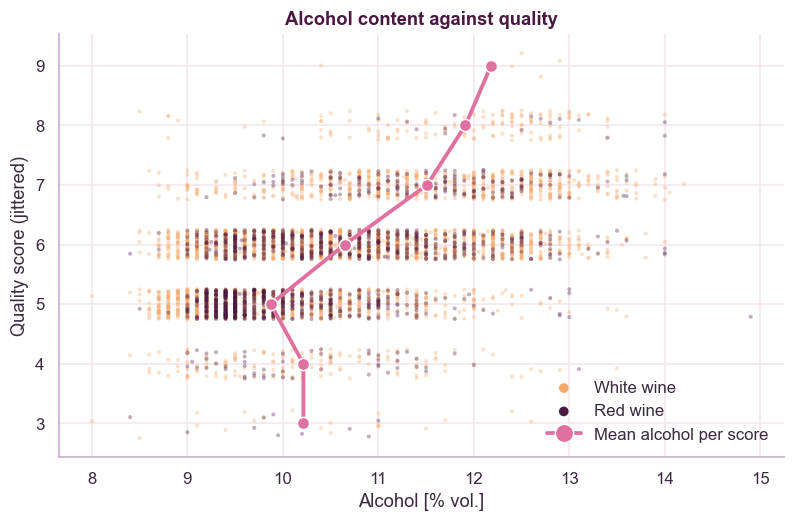

In [9]:
rng = np.random.default_rng(0)
jitter = rng.uniform(-0.25, 0.25, len(wine))
fig, ax = plt.subplots(figsize=(8.5, 5))
for t in ["white", "red"]:
    m = wine.wine_type == t
    ax.scatter(wine.loc[m, "alcohol"], wine.loc[m, "quality"] + jitter[m], s=7, alpha=0.35,
               color=TYPE_COLORS[t], label=f"{t.capitalize()} wine", edgecolor="none")
means = wine.groupby("quality")["alcohol"].mean()
ax.plot(means.values, means.index, "o-", color=PINK, lw=2.5, ms=8,
        markeredgecolor="white", label="Mean alcohol per score")
ax.set_xlabel("Alcohol [% vol.]")
ax.set_ylabel("Quality score (jittered)")
ax.set_title("Alcohol content against quality")
ax.legend(loc="lower right", markerscale=1.5)
for h in ax.get_legend().legend_handles[:2]:
    h.set_alpha(1)
    h.set_sizes([40])
save(fig, "eda_scatter_alcohol_quality.png")
plt.show()

### A.4 Correlation matrix (Pearson)

Figure saved -> ../results/figures/eda_correlation_matrix.png


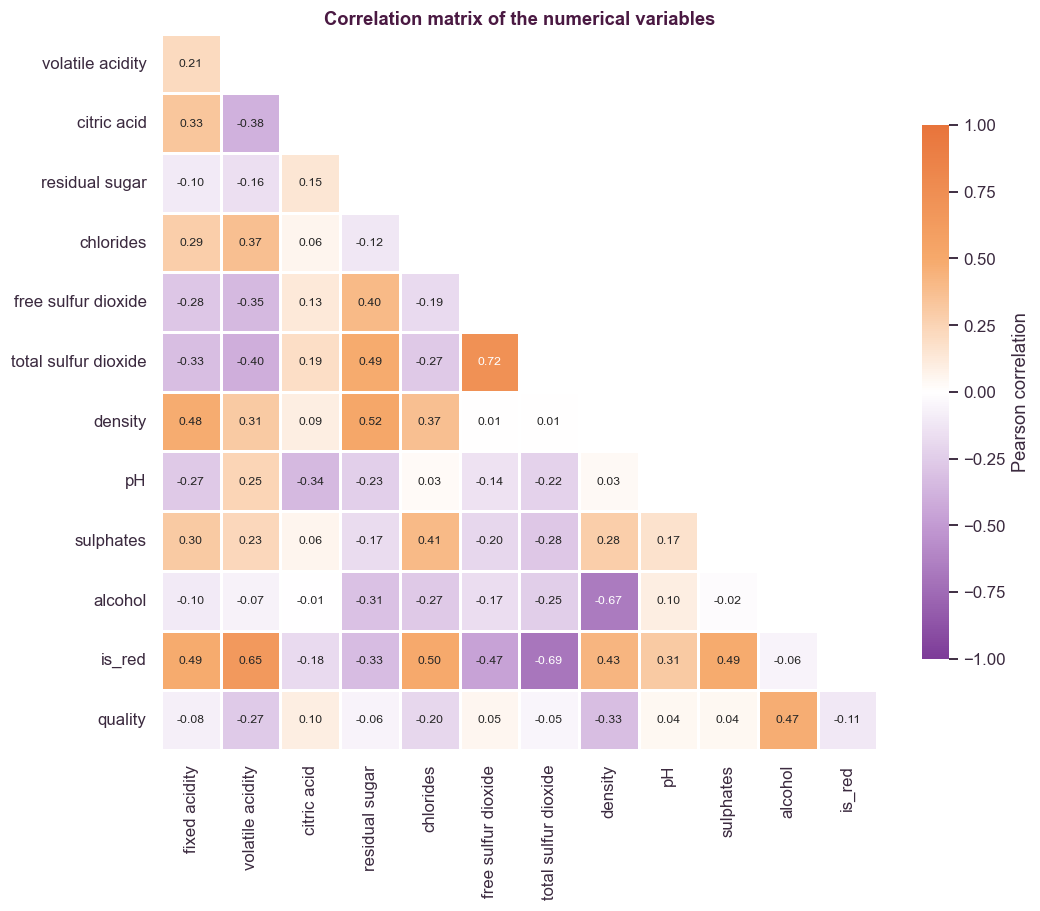

In [10]:
cols = FEATURES + ["is_red", "quality"]
corr = wine[cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(10.5, 9))
sns.heatmap(corr.iloc[1:, :-1], mask=mask[1:, :-1], cmap=CMAP_DIV, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=0.8, linecolor="white", square=True,
            cbar_kws={"shrink": 0.7, "label": "Pearson correlation"}, ax=ax)
ax.grid(False)
ax.set_title("Correlation matrix of the numerical variables")
save(fig, "eda_correlation_matrix.png")
plt.show()

,Pearson,Spearman
density,-0.326,-0.349
volatile acidity,-0.265,-0.251
chlorides,-0.202,-0.304
is_red,-0.115,-0.120
fixed acidity,-0.080,-0.104
residual sugar,-0.057,-0.028
total sulfur dioxide,-0.050,-0.058
pH,0.040,0.053
sulphates,0.042,0.036
free sulfur dioxide,0.054,0.090


Figure saved -> ../results/figures/eda_correlation_with_quality.png


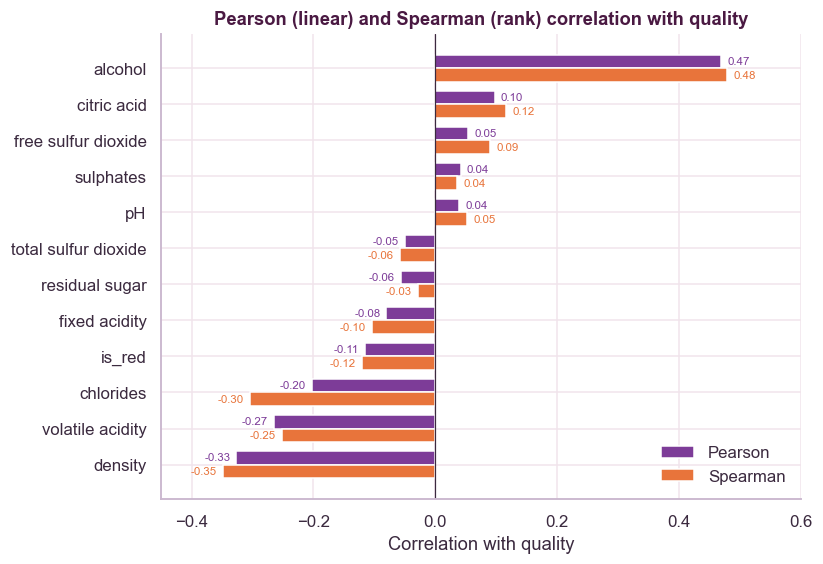

chlorides         density           0.237
                  is_red            0.169
                  alcohol           0.148
volatile acidity  residual sugar    0.142
chlorides         pH                0.134
dtype: float64


In [11]:
spearman = wine[cols].corr(method="spearman")
corr_q = pd.DataFrame({"Pearson": corr["quality"], "Spearman": spearman["quality"]}).drop("quality")
corr_q = corr_q.sort_values("Pearson")
display(corr_q.round(3))
corr_q.round(4).to_csv("../results/eda_correlation_with_quality.csv")

pos = np.arange(len(corr_q))
h = 0.38
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.barh(pos + h / 2, corr_q["Pearson"], height=h, color=PURPLE, edgecolor="white", label="Pearson")
ax.barh(pos - h / 2, corr_q["Spearman"], height=h, color=ORANGE, edgecolor="white", label="Spearman")
for i, v in enumerate(corr_q["Pearson"]):
    ax.text(v + (0.01 if v >= 0 else -0.01), i + h / 2, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=7.5, color=PURPLE)
for i, v in enumerate(corr_q["Spearman"]):
    ax.text(v + (0.01 if v >= 0 else -0.01), i - h / 2, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=7.5, color=ORANGE)
ax.set_yticks(pos, corr_q.index)
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlim(-0.45, 0.6)
ax.set_xlabel("Correlation with quality")
ax.set_title("Pearson (linear) and Spearman (rank) correlation with quality")
ax.legend(loc="lower right")
save(fig, "eda_correlation_with_quality.png")
plt.show()

# variable pairs where the rank correlation differs most from the linear one
pairs = (spearman - corr).where(np.triu(np.ones_like(corr, dtype=bool), 1)).stack()
print(pairs.abs().sort_values(ascending=False).head(5).round(3))

Alcohol is the variable most related to quality (positive). Density, volatile acidity and
chlorides have negative correlations. Using the scale of Schober et al. (2018), the correlation
with quality is moderate for alcohol, weak for density, volatile acidity and chlorides, and
negligible or weak for the rest, so one variable alone is not enough. Some inputs are also correlated between them (density with
alcohol and residual sugar, free with total sulfur dioxide), so part of their information is
repeated.

### A.5 Scatter plots in pairs (random sample of 1,500 wines)

Figure saved -> ../results/figures/eda_pairplot.png


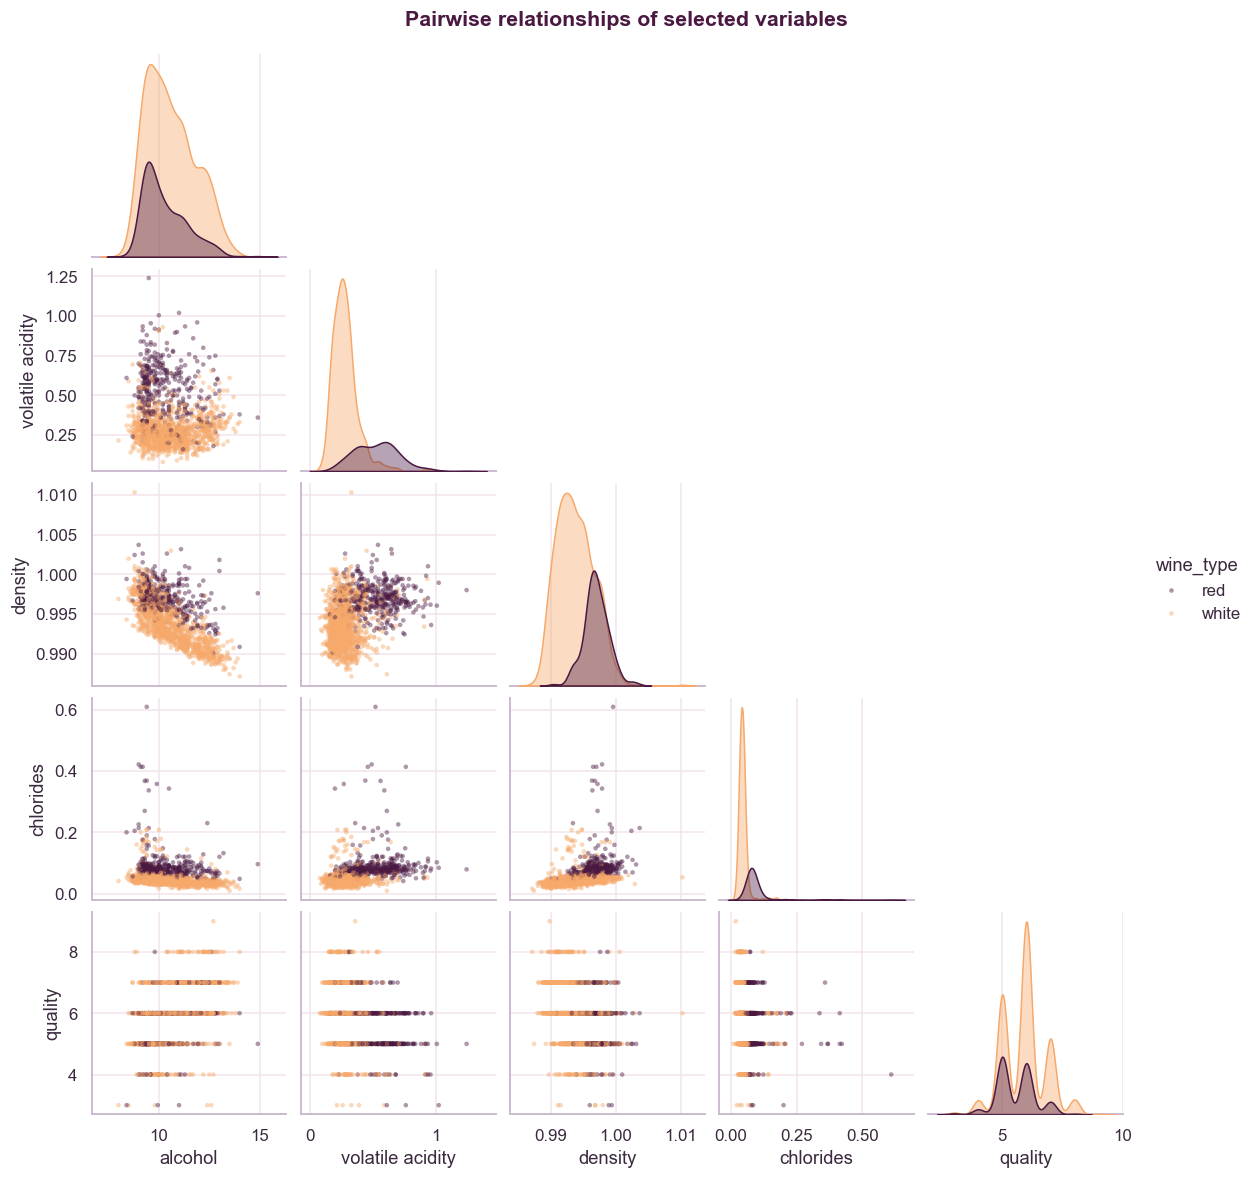

In [12]:
sample = wine.sample(1500, random_state=0)
g = sns.pairplot(sample, vars=["alcohol", "volatile acidity", "density", "chlorides", "quality"],
                 hue="wine_type", palette=TYPE_COLORS, corner=True, height=2.1,
                 plot_kws={"s": 9, "alpha": 0.45, "edgecolor": "none"},
                 diag_kws={"fill": True, "alpha": 0.4})
g.figure.suptitle("Pairwise relationships of selected variables", y=1.02,
                  color=PLUM, weight="semibold", fontsize=14)
save(g.figure, "eda_pairplot.png")
plt.show()

### A.6 Multiple linear regression
We fit a linear regression with standardised inputs on all the data, just to see the sign and the
weight of each variable when they are used together. The real evaluation of the models is done
later with nested cross-validation.

R² on the same data (descriptive only): 0.3112   adjusted R²: 0.3096
Figure saved -> ../results/figures/eda_linear_coefficients.png


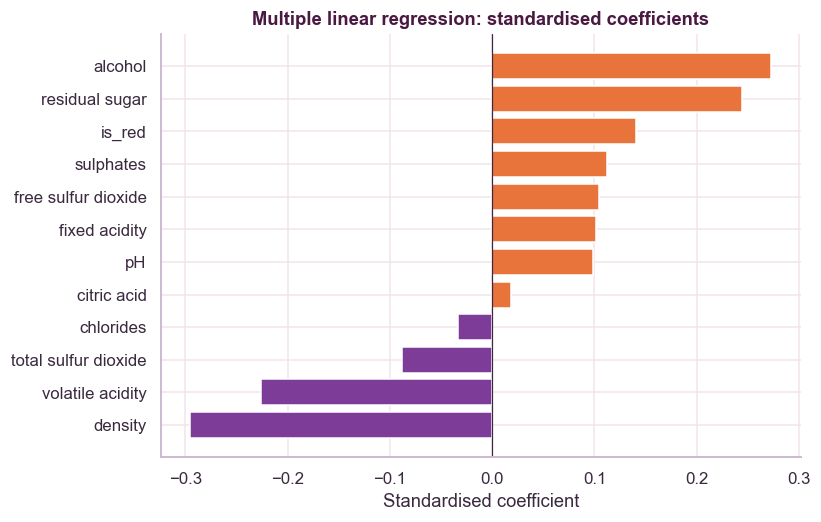

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

inputs = FEATURES + ["is_red"]
X_std = StandardScaler().fit_transform(wine[inputs])
lin = LinearRegression().fit(X_std, wine["quality"])
coef = pd.Series(lin.coef_, index=inputs).sort_values()
n, p = X_std.shape
r2 = lin.score(X_std, wine["quality"])
r2_adj = 1 - (1 - r2) * (n - 1) / (n - p - 1)
pd.DataFrame({"n": [n], "p": [p], "R2": [r2], "adjusted R2": [r2_adj]}).to_csv(
    "../results/eda_linear_regression_r2.csv", index=False)
print(f"R² on the same data (descriptive only): {r2:.4f}   adjusted R²: {r2_adj:.4f}")

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(coef.index, coef.values, color=[PURPLE if v < 0 else ORANGE for v in coef], edgecolor="white")
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel("Standardised coefficient")
ax.set_title("Multiple linear regression: standardised coefficients")
save(fig, "eda_linear_coefficients.png")
plt.show()

The linear model explains only a small part of the variance. Residual sugar gets a big positive
coefficient even though its correlation with quality is almost zero. This happens because density
depends on alcohol and sugar, so once density is in the model sugar works as a correction. This is
multicollinearity, so the coefficients have to be read carefully.

---
# B. EDA for classification

### B.1 Class balance

Figure saved -> ../results/figures/eda_class_distribution.png


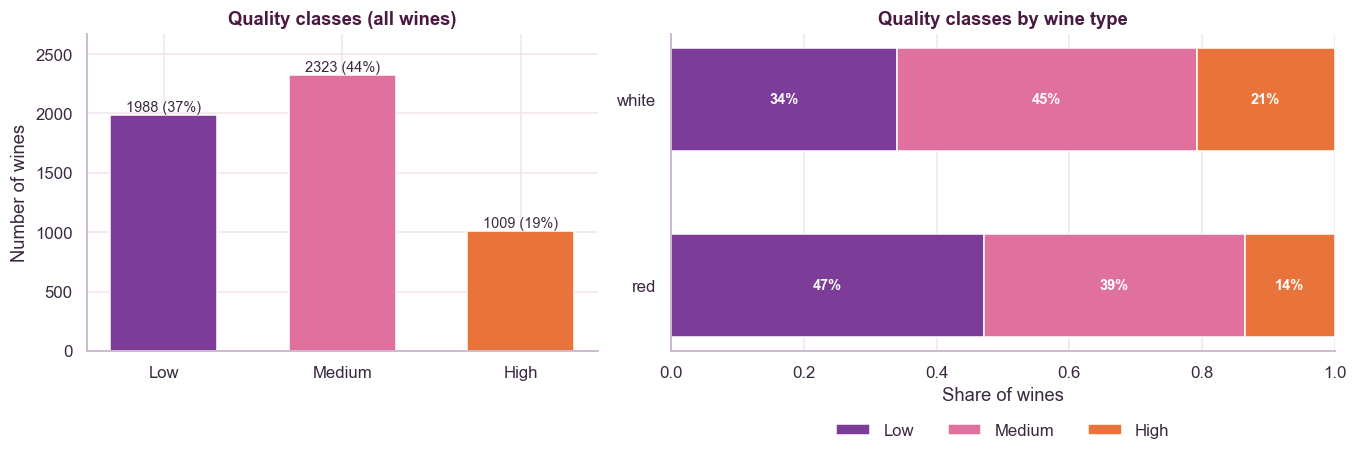

Majority-class baseline accuracy: 0.437


In [14]:
counts = wine["quality_class"].value_counts().reindex(CLASS_ORDER)
props = counts / counts.sum()
share = pd.crosstab(wine["wine_type"], wine["quality_class"], normalize="index")[CLASS_ORDER]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].bar(CLASS_ORDER, counts, color=[CLASS_COLORS[c] for c in CLASS_ORDER], width=0.6)
for i, (n, p) in enumerate(zip(counts, props)):
    axes[0].text(i, n + 30, f"{n} ({p:.0%})", ha="center", fontsize=9.5)
axes[0].set_ylim(0, counts.max() * 1.15)
axes[0].set_ylabel("Number of wines")
axes[0].set_title("Quality classes (all wines)")

left = np.zeros(len(share))
for c in CLASS_ORDER:
    axes[1].barh(share.index, share[c], left=left, color=CLASS_COLORS[c], label=c, height=0.55)
    for i, v in enumerate(share[c]):
        axes[1].text(left[i] + v / 2, i, f"{v:.0%}", ha="center", va="center", color="white",
                     fontsize=9.5, weight="bold")
    left += share[c].values
axes[1].set_xlim(0, 1)
axes[1].set_xlabel("Share of wines")
axes[1].set_title("Quality classes by wine type")
axes[1].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
fig.tight_layout()
save(fig, "eda_class_distribution.png")
plt.show()
print(f"Majority-class baseline accuracy: {props.max():.3f}")

The classes are imbalanced and High is the smallest one. Accuracy alone can be misleading, so for
the models we use stratified folds and the macro F1-score, where every class counts the same.

### B.2 Histograms of alcohol for each class

Figure saved -> ../results/figures/eda_histograms_by_class.png


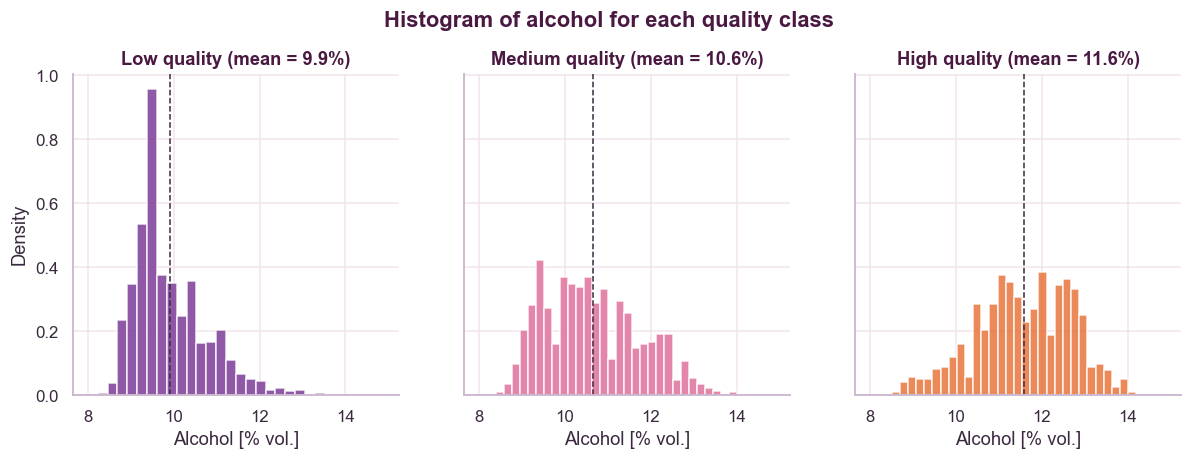

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
for ax, c in zip(axes, CLASS_ORDER):
    values = wine.loc[wine.quality_class == c, "alcohol"]
    ax.hist(values, bins=30, color=CLASS_COLORS[c], alpha=0.85, edgecolor="white", density=True)
    ax.axvline(values.mean(), color=INK, ls="--", lw=1)
    ax.set_title(f"{c} quality (mean = {values.mean():.1f}%)")
    ax.set_xlabel("Alcohol [% vol.]")
axes[0].set_ylabel("Density")
fig.suptitle("Histogram of alcohol for each quality class", color=PLUM, weight="semibold", y=1.03)
save(fig, "eda_histograms_by_class.png")
plt.show()

### B.3 Distributions of the most relevant features by class

Figure saved -> ../results/figures/eda_overlap_by_class.png


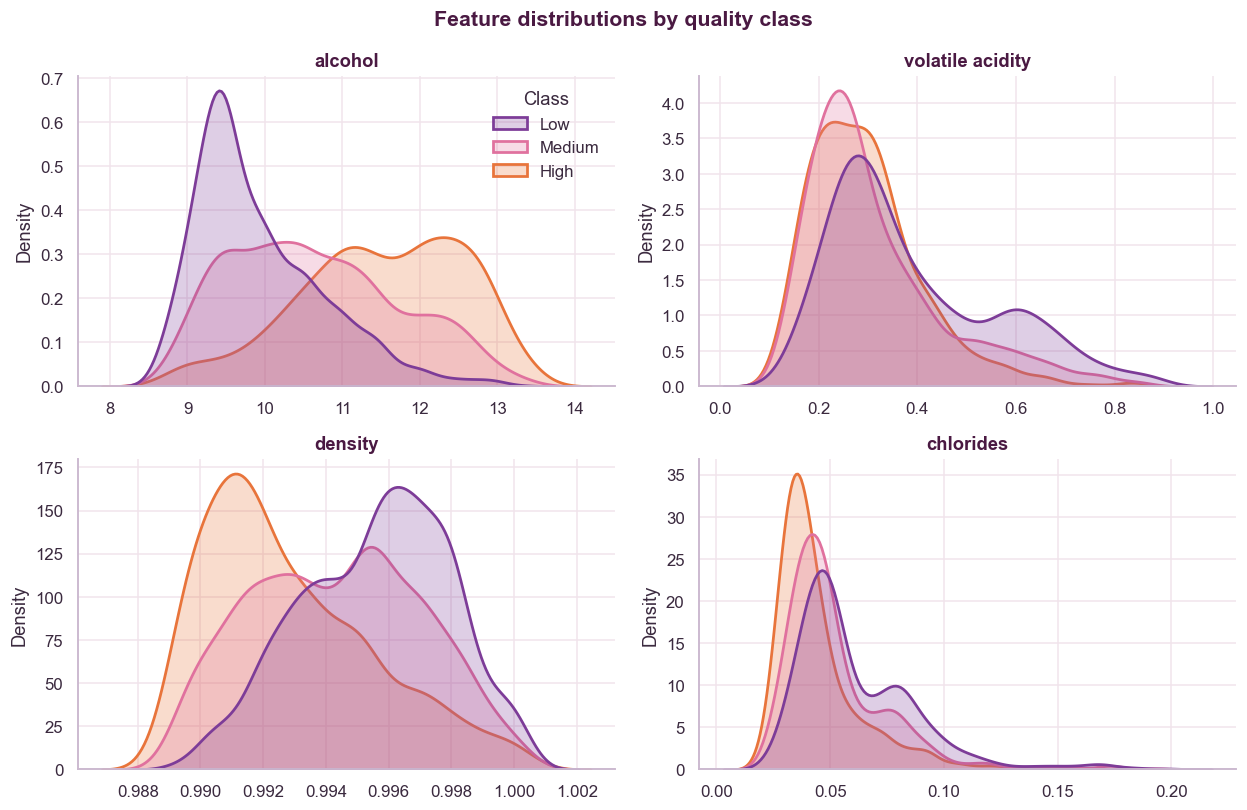

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.5))
for ax, col in zip(axes.flat, ["alcohol", "volatile acidity", "density", "chlorides"]):
    lo, hi = wine[col].quantile([0.01, 0.99])
    sub = wine[(wine[col] >= lo) & (wine[col] <= hi)]
    sns.kdeplot(data=sub, x=col, hue="quality_class", hue_order=CLASS_ORDER, palette=CLASS_COLORS,
                fill=True, common_norm=False, alpha=0.25, linewidth=1.8, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    if ax is not axes.flat[0]:
        ax.get_legend().remove()
    else:
        ax.get_legend().set_title("Class")
fig.suptitle("Feature distributions by quality class", color=PLUM, weight="semibold", fontsize=14)
fig.tight_layout()
save(fig, "eda_overlap_by_class.png")
plt.show()

### B.4 Scatter plots by class: alcohol vs volatile acidity

Figure saved -> ../results/figures/eda_scatter_by_class.png


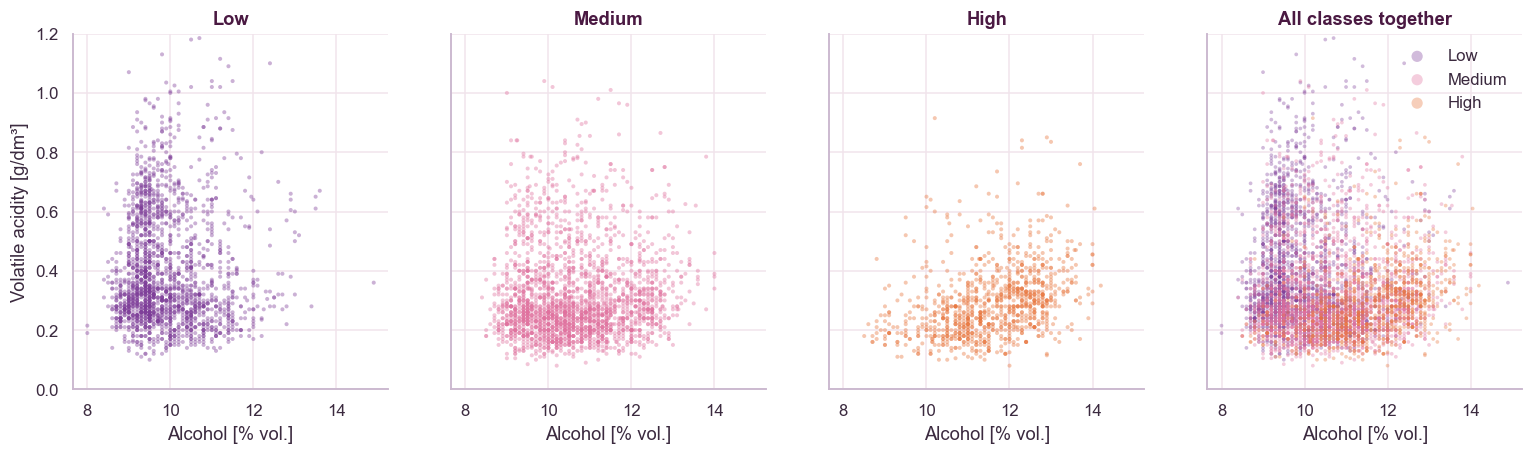

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharex=True, sharey=True)
for ax, c in zip(axes[:3], CLASS_ORDER):
    sub = wine[wine.quality_class == c]
    ax.scatter(sub["alcohol"], sub["volatile acidity"], s=7, alpha=0.4, color=CLASS_COLORS[c],
               edgecolor="none")
    ax.set_title(c)
for c in CLASS_ORDER:
    sub = wine[wine.quality_class == c]
    axes[3].scatter(sub["alcohol"], sub["volatile acidity"], s=6, alpha=0.35,
                    color=CLASS_COLORS[c], edgecolor="none", label=c)
axes[3].set_title("All classes together")
axes[3].legend(markerscale=3)
for ax in axes:
    ax.set_xlabel("Alcohol [% vol.]")
axes[0].set_ylabel("Volatile acidity [g/dm³]")
axes[0].set_ylim(0, 1.2)
save(fig, "eda_scatter_by_class.png")
plt.show()

High wines are more common with high alcohol and low volatile acidity, and Low wines in the opposite
corner, but the three groups overlap a lot. Two variables are not enough to separate the classes.

### B.5 Kruskal-Wallis test
Non-parametric test (it doesn't assume normality) to check if a variable has the same distribution
in the three classes. With so many wines almost everything is significant, so we also look at the
effect size $\varepsilon^2 = (H - k + 1)/(n - k)$.

,H statistic,p-value,epsilon²
feature,,,
alcohol,1302.3,1.62e-283,0.245
density,700.6,7.53e-153,0.131
chlorides,518.6,2.40e-113,0.097
volatile acidity,369.8,5.01e-81,0.069
citric acid,67.2,2.61e-15,0.012
fixed acidity,57.7,3.03e-13,0.010
free sulfur dioxide,33.7,4.90e-08,0.006
total sulfur dioxide,29.4,4.08e-07,0.005
pH,19.1,7.23e-05,0.003


Figure saved -> ../results/figures/eda_kruskal_wallis.png


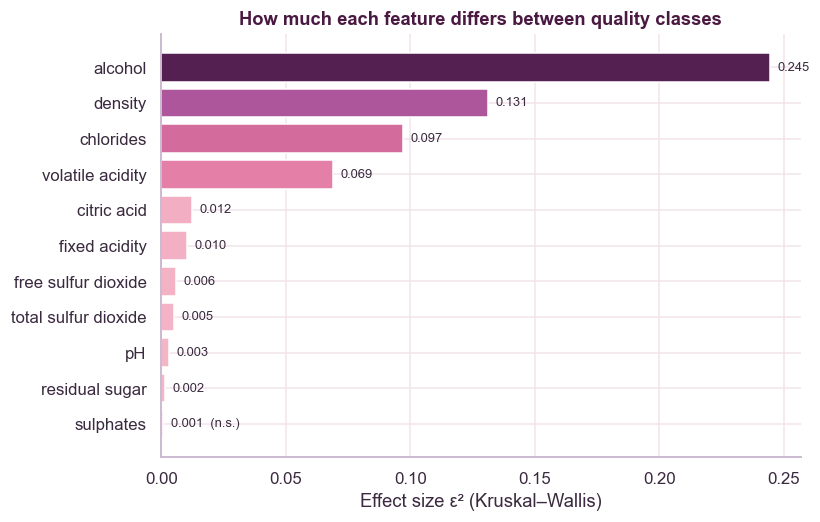

In [18]:
from scipy import stats

n, k = len(wine), len(CLASS_ORDER)
rows = []
for col in FEATURES:
    groups = [wine.loc[wine.quality_class == c, col] for c in CLASS_ORDER]
    H, p = stats.kruskal(*groups)
    rows.append([col, H, p, (H - k + 1) / (n - k)])
kw = (pd.DataFrame(rows, columns=["feature", "H statistic", "p-value", "epsilon²"])
        .set_index("feature").sort_values("epsilon²", ascending=False))
display(kw.style.format({"H statistic": "{:.1f}", "p-value": "{:.2e}", "epsilon²": "{:.3f}"}))

colors = [CMAP_SEQ(0.25 + 0.7 * v / kw["epsilon²"].max()) for v in kw["epsilon²"]]
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(kw.index, kw["epsilon²"], color=colors, edgecolor="white")
for i, (e, p) in enumerate(zip(kw["epsilon²"], kw["p-value"])):
    ax.text(e + 0.003, i, f"{e:.3f}" + ("" if p < 0.05 / len(FEATURES) else "  (n.s.)"),
            va="center", fontsize=8.5)
ax.invert_yaxis()
ax.set_xlabel("Effect size ε² (Kruskal–Wallis)")
ax.set_title("How much each feature differs between quality classes")
save(fig, "eda_kruskal_wallis.png")
plt.show()

---
## Summary of the EDA

* Quality scores are concentrated in 5 and 6, extreme scores are rare.
* The classes are imbalanced (High is the smallest), so we use stratified folds and macro F1.
* The most relevant variables are alcohol (positive), and density, volatile acidity and chlorides
  (negative).
* Some variables are correlated between them (density, alcohol, sugar; free and total SO2).
* The classes overlap a lot, so non-linear models will probably work better than linear ones.
* Red and white wines are chemically very different (large Cliff's delta in most variables), but
  alcohol is almost the same in both types, so we include `is_red` as an input.
* The scales are very different, so linear models, KNN and SVM need standardisation.